# Guided Project 02 · PyTorch DQN 训练 CartPole

[返回项目目录](README.md) · [对应 Chapter06](../02_chapters/Chapter06.ipynb) · [DQN 扩展](../02_chapters/Chapter08.ipynb)

这个项目把预备篇的 NumPy、Matplotlib、PyTorch、Gymnasium 与 DQN 公式真正连起来。目标不是追求最高分，而是理解一条 transition 如何变成一次网络更新。


## 1. DQN 数据流

```text
observation → online network → epsilon-greedy action → env.step
            → replay buffer → random batch
            → online Q(s,a) 与 target y → Huber loss → optimizer
```

使用 Double DQN target：

$$a^*=\arg\max_a Q_\theta(s',a),\qquad
y=r+\gamma(1-d)Q_{\theta^-}(s',a^*)$$

`terminated` 决定 $d$；时间截断结束 episode，但不自动把未来价值设为 0。


In [1]:
from collections import deque
import random
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
from torch import nn

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(1)
device = torch.device("cpu")

env = gym.make("CartPole-v1")
obs, _ = env.reset(seed=SEED)
print("observation/action:", obs.shape, env.action_space)
env.close()


observation/action: (4,) Discrete(2)


## 2. 先测随机基线

如果训练后的 agent 没有明显超过随机动作，就不能说“学会了”。CartPole 随机策略通常只能维持十几到几十步。


In [2]:
def random_cartpole(episodes=20, seed=42):
    baseline_env = gym.make("CartPole-v1")
    rng = np.random.default_rng(seed); scores = []
    for episode in range(episodes):
        state, _ = baseline_env.reset(seed=seed+episode); total = 0.0
        for _ in range(500):
            state, reward, terminated, truncated, _ = baseline_env.step(int(rng.integers(2)))
            total += reward
            if terminated or truncated: break
        scores.append(total)
    baseline_env.close()
    return np.asarray(scores)

random_scores = random_cartpole()
print("random mean/min/max:", random_scores.mean(), random_scores.min(), random_scores.max())


random mean/min/max: 31.05 11.0 87.0


## 3. 网络和 replay buffer

网络输入 `(B,4)`、输出 `(B,2)`。Replay buffer 保存原始 transition；采样时再转换成 tensor，便于检查 shape 和 dtype。


In [3]:
class DQN(nn.Module):
    def __init__(self, obs_size=4, n_actions=2):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(obs_size, 64), nn.ReLU(),
                                 nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, n_actions))
    def forward(self, x):
        return self.net(x)

class ReplayBuffer:
    def __init__(self, capacity=20_000):
        self.data = deque(maxlen=capacity)
    def append(self, transition): self.data.append(transition)
    def sample(self, batch_size, rng):
        indices = rng.choice(len(self.data), size=batch_size, replace=False)
        columns = list(zip(*(self.data[i] for i in indices)))
        return tuple(np.asarray(column) for column in columns)
    def __len__(self): return len(self.data)

test_net = DQN()
assert test_net(torch.zeros(3, 4)).shape == (3, 2)
print(test_net)


DQN(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)


## 4. 一次 batch 更新：逐行对应公式

- `gather` 取得实际动作的 $Q(s,a)$。
- online network 在下一状态选动作。
- target network 评价该动作。
- 只有真正 `terminated` 才移除 bootstrap。


In [4]:
def update_batch(online, target, optimizer, batch, gamma=.99):
    states, actions, rewards, next_states, terminated = batch
    states_t = torch.as_tensor(states, dtype=torch.float32, device=device)
    actions_t = torch.as_tensor(actions, dtype=torch.int64, device=device)
    rewards_t = torch.as_tensor(rewards, dtype=torch.float32, device=device)
    next_states_t = torch.as_tensor(next_states, dtype=torch.float32, device=device)
    terminated_t = torch.as_tensor(terminated, dtype=torch.bool, device=device)

    chosen_q = online(states_t).gather(1, actions_t.unsqueeze(1)).squeeze(1)
    with torch.no_grad():
        next_actions = online(next_states_t).argmax(dim=1, keepdim=True)
        next_q = target(next_states_t).gather(1, next_actions).squeeze(1)
        expected_q = rewards_t + gamma*(~terminated_t).float()*next_q
    loss = nn.functional.smooth_l1_loss(chosen_q, expected_q)
    optimizer.zero_grad(); loss.backward()
    nn.utils.clip_grad_norm_(online.parameters(), 10.0)
    optimizer.step()
    return loss.item(), chosen_q.detach().mean().item()


## 5. 完整训练

先收集 500 条经验再更新；epsilon 按环境步数下降；target 每 250 步同步。曲线同时记录 return、loss、Q 均值和 epsilon，避免只凭一条曲线判断。


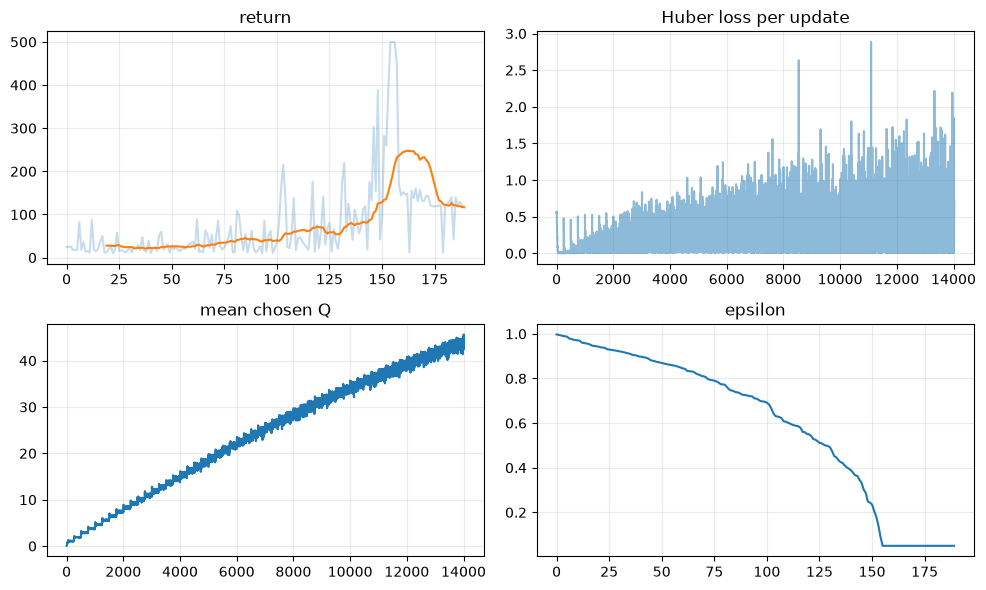

last-20 training return: 116.6 updates: 14021


In [5]:
def train_dqn(seed=42, episodes=190):
    rng = np.random.default_rng(seed)
    env = gym.make("CartPole-v1")
    online, target = DQN().to(device), DQN().to(device)
    target.load_state_dict(online.state_dict())
    optimizer = torch.optim.Adam(online.parameters(), lr=8e-4)
    buffer = ReplayBuffer()
    returns, losses, q_means, epsilons = [], [], [], []
    total_steps = 0
    for episode in range(episodes):
        state, _ = env.reset(seed=seed+episode)
        total = 0.0
        for _ in range(500):
            epsilon = max(.05, 1.0-total_steps/10_000)
            if rng.random() < epsilon:
                action = int(rng.integers(2))
            else:
                with torch.no_grad():
                    action = int(online(torch.as_tensor(state, dtype=torch.float32).unsqueeze(0)).argmax())
            next_state, reward, terminated, truncated, _ = env.step(action)
            buffer.append((state, action, reward, next_state, terminated))
            state, total, total_steps = next_state, total+reward, total_steps+1
            if len(buffer) >= 500:
                loss, q_mean = update_batch(online, target, optimizer, buffer.sample(64, rng))
                losses.append(loss); q_means.append(q_mean)
            if total_steps % 250 == 0:
                target.load_state_dict(online.state_dict())
            if terminated or truncated: break
        returns.append(total); epsilons.append(epsilon)
    env.close()
    return online, np.asarray(returns), np.asarray(losses), np.asarray(q_means), np.asarray(epsilons)

online, returns, losses, q_means, epsilons = train_dqn()
window = 20
smooth_return = np.convolve(returns, np.ones(window)/window, mode="valid")
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes[0,0].plot(returns, alpha=.25); axes[0,0].plot(np.arange(window-1,len(returns)), smooth_return); axes[0,0].set_title("return")
axes[0,1].plot(losses, alpha=.5); axes[0,1].set_title("Huber loss per update")
axes[1,0].plot(q_means); axes[1,0].set_title("mean chosen Q")
axes[1,1].plot(epsilons); axes[1,1].set_title("epsilon")
for ax in axes.flat: ax.grid(alpha=.25)
plt.tight_layout(); plt.show(); plt.close()
print("last-20 training return:", round(returns[-20:].mean(), 1), "updates:", len(losses))


## 6. 独立评估

训练回报包含 epsilon 探索，不能直接当最终性能。评估使用新环境、greedy action、`eval()` 和 `no_grad()`，且不写 replay、不更新参数。


In [6]:
def evaluate_dqn(model, episodes=20):
    env = gym.make("CartPole-v1")
    model.eval(); scores = []
    with torch.no_grad():
        for episode in range(episodes):
            state, _ = env.reset(seed=10_000+episode); total = 0.0
            for _ in range(500):
                action = int(model(torch.as_tensor(state, dtype=torch.float32).unsqueeze(0)).argmax())
                state, reward, terminated, truncated, _ = env.step(action)
                total += reward
                if terminated or truncated: break
            scores.append(total)
    env.close()
    return np.asarray(scores)

evaluation = evaluate_dqn(online)
print("evaluation mean/min/max:", evaluation.mean(), evaluation.min(), evaluation.max())
assert evaluation.mean() > random_scores.mean() * 2


evaluation mean/min/max: 137.5 126.0 148.0


## 7. 怎样诊断，而不是盲目调参

- return 不升：先查 action、reward、terminal mask、target 与 replay 数据。
- loss 降但 return 不升：target 可能自洽但错误，或评估/探索有问题。
- Q 持续远超最大可能回报：检查终止 bootstrap、reward scale 和 target 同步。
- epsilon 已很低但经验池没有成功轨迹：探索下降过快。
- 单 seed 很好：不能证明稳定；正式报告至少跑 3–5 个 seed。

**故障练习：**把 terminal mask 删除、target sync 改为每步、epsilon decay 改为 500 步。运行前先写下各自可能出现的曲线。


## 8. 项目验收与下一步

你应能不看代码回答：

1. replay buffer 为什么让 SGD 更合理？
2. online/target 分别在哪一步出现？
3. `gather` 的输入输出 shape 是什么？
4. 为什么 `terminated` 与 `truncated` 分开保存？
5. 为什么训练 return 和评估 return 不同？

完成后进入 [Chapter06](../02_chapters/Chapter06.ipynb)，再用 [Chapter08](../02_chapters/Chapter08.ipynb)逐项加入 Double、n-step、Dueling 或 PER。不要一次组合全部扩展。
